Acá deberíamos armar el primer ejemplo principal que condense todo y quede bien presentado.
Sugiero tomar el caso del agua y armar:

* Curva de equilibrio líquido-vapor
* Definir un rango de presión y temperatura acorde y evaluar las propiedades del vapor en esa región.
* Crear gráficos de T vs h a p constante (serían datos muy directos de obtener)

Hacer lo anterior para la web y con uno de los paquetes. Graficar ambos resultados en simultáneo

Algo no funciona de las unidades, cuando pedimos IsoBar en unidades de kPa, las toma como en MPa siempre. 

Corregir para que no interpole los valores dentro de la campana

In [82]:
from thermo_pkg_nist_compare.substancelist import Substance
from thermo_pkg_nist_compare.datos_nist_web import busqueda_web_nist
import numpy as np
from thermo_pkg_nist_compare.graficadora import graficar

import CoolProp.CoolProp as CP
from thermo_pkg_nist_compare.propdata import PropData


In [48]:
#Necesitamos los datos de Lsat y Vsat

tabla_liq, tabla_vap = busqueda_web_nist(
    tipo_busq="SatP",
    iso_value=None,
    rg_min=293,
    rg_max=647,
    rg_interval=10,
    unidades = {
        "PUnit": "kPa",
        "HUnit": "kJ/kg",
        "DUnit": "kg/m3",
        },
)

#print("Propiedades de la fase líquida:\n")
#print(tabla_liq)

#print("\nPropiedades de la fase vapor:\n")
#print(tabla_vap)

In [ ]:
#tomamos los valores de T y de h

#Conviene trabajar con los alias

table_red_liq = tabla_liq[["T", "P", "u", "h", "s"]]

table_red_vap = tabla_vap[["T", "P", "u", "h", "s"]]

#print(table_red)

T_sat = table_red_liq["T"]

h_liq = table_red_liq["h"]

h_vap = table_red_vap["h"]

#Luego, conviene ordenarlos por isobara.
#Para cada valor de P : Tsat, Tsat ...Tmax , h_liq, h... (la de vap sat sale de vsc)
#h_nist = np.concatenate((h_liq, h_vap))
#T_nist = np.concatenate((T_sat, T_sat))

#print(np.shape(T_nist))

(72,)


In [100]:
#Como así también los datos de VSC a cada P de la tabla anterior.
#En un rango de T que cubra desde la Tsat hasta Tmax > Tsat.

data_table_vsc = busqueda_web_nist(
        tipo_busq="IsoBar",
        iso_value=table_red_liq["P"][10],
        rg_min=table_red_liq["T"][10],
        rg_max=800,
        rg_interval=10,
        unidades = {
            "PUnit": "MPa",
            "HUnit": "kJ/kg",
            "Tunidades": "ºC",
            "DUnit": "kg/m^3",
            },
)



In [101]:
#Extraigo los valores

T_vsc = data_table_vsc["T"]
h_vsc = data_table_vsc["h"]

In [96]:
i = 0
T0 = T_sat[i]
hL = h_liq[i]
hV = h_vap[i]

# La consulta de VSC empieza en Tsat; si su primer punto coincide
# con el vapor saturado, lo omitimos para no duplicar ese punto.
inicio = 1 if (
    np.isclose(T_vsc[0], T0) and np.isclose(h_vsc[0], hV)
) else 0

T_isobar = np.concatenate(([T0, T0], T_vsc[inicio:]))
h_isobar = np.concatenate(([hL, hV], h_vsc[inicio:]))

#graficar(h_isobar, T_isobar)

In [102]:
#Extraigo los datos del paquete CoolProp

model_disp={"IAPWS95":"Water","IAPWS-97":"IF97::Water"}

modelo = "IAPWS95"  # Para pruebas rápidas, se puede cambiar a "IAPWS-97"

P_CP = data_table_vsc["P"]*1000    # kPa

print(P_CP)

T_CP = T_vsc   # K

u_CP = CP.PropsSI("Umass", "P", P_CP*1000, "T", T_vsc, model_disp[modelo])/1000 # kJ/(kg K)
h_CP = CP.PropsSI("Hmass", "P", P_CP*1000, "T", T_vsc, model_disp[modelo])/1000  # kJ/kg
s_CP = CP.PropsSI("Smass", "P", P_CP*1000, "T", T_vsc, model_disp[modelo])/1000 # kJ/kg
    
encabezados = ["T", "P", "u", "h", "s"]

unidades = {"T": "K", "P": "kPa", "u": "kJ/kg", "h" : "kJ/kg", "s":"kJ/kg*K"}

tabla_array = np.column_stack((T_vsc, P_CP, u_CP, h_CP, s_CP))

tabla = PropData(datos=tabla_array, encabezados=encabezados, unidades=unidades)

#print(tabla)


[197.73238775 197.73238775 197.73238775 197.73238775 197.73238775
 197.73238775 197.73238775 197.73238775 197.73238775 197.73238775
 197.73238775 197.73238775 197.73238775 197.73238775 197.73238775
 197.73238775 197.73238775 197.73238775 197.73238775 197.73238775
 197.73238775 197.73238775 197.73238775 197.73238775 197.73238775
 197.73238775 197.73238775 197.73238775 197.73238775 197.73238775
 197.73238775 197.73238775 197.73238775 197.73238775 197.73238775
 197.73238775 197.73238775 197.73238775 197.73238775 197.73238775
 197.73238775 197.73238775 197.73238775 197.73238775]


In [104]:
P_sat = 101325.0  # Pa

T_sat = CP.PropsSI("T", "P", P_sat, "Q", 0, "Water")
h_f = CP.PropsSI("H", "P", P_sat, "Q", 0, "Water")   # Líquido saturado
h_g = CP.PropsSI("H", "P", P_sat, "Q", 1, "Water")   # Vapor saturado
h_fg = h_g - h_f                                  # Calor latente de vaporización

print(f"T_sat: {T_sat:.2f} K ({T_sat - 273.15:.2f} °C)")
print(f"h_f: {h_f/1000:.2f} kJ/kg | h_g: {h_g/1000:.2f} kJ/kg | h_fg: {h_fg/1000:.2f} kJ/kg")


T_sat: 373.12 K (99.97 °C)
h_f: 419.06 kJ/kg | h_g: 2675.53 kJ/kg | h_fg: 2256.47 kJ/kg


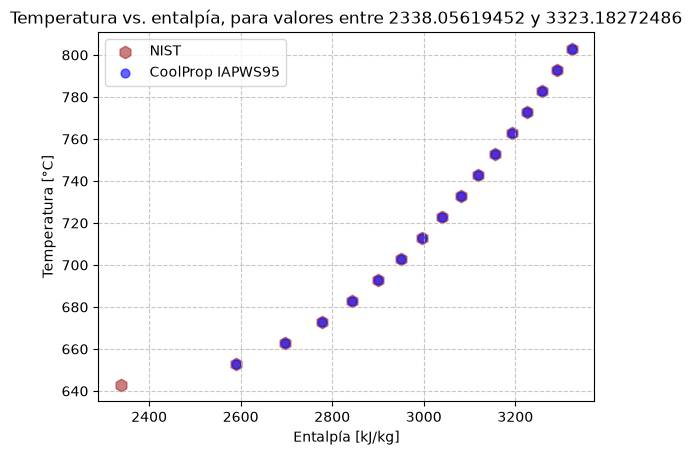

In [99]:
graficar(h_vsc, T_vsc, x_comp=h_CP, y_comp=T_vsc, label_2="CoolProp "+modelo, nombre_x="Entalpía", nombre_y="Temperatura", unidad_x="kJ/kg", unidad_y="°C", color='brown', linewidth=0.7, markersize=80, interpolar=False)